# Lung Disease Classification — Hybrid VGG16 + ViT (CBAM + CLAHE + Grad-CAM++)

**Self-contained notebook** — all code is inline, no external project files needed.

- **CLAHE** — contrast-limited adaptive histogram equalisation of every X-ray (cached to disk).
- **VGG16** — ImageNet-pretrained CNN backbone (`torchvision.models.vgg16().features`, 512 x 7 x 7).
- **CBAM** — channel + spatial attention on the VGG16 feature map.
- **ViT** — transformer encoder over the 7 x 7 = 49 CBAM feature tokens (+ CLS token).
- **Grad-CAM++** — visual explanations hooked on the CBAM output, with quantitative faithfulness metrics.
- **Evaluation metrics** — accuracy, balanced accuracy, precision / recall (sensitivity) / specificity / NPV / F1
  (per class, macro, weighted), ROC-AUC, PR-AUC, Cohen's kappa, MCC, log-loss, top-2 accuracy,
  confusion matrices, ROC and PR curves.

```
X-ray -> CLAHE -> VGG16 (.features) -> CBAM -> { global-avg-pool branch , ViT branch } -> concat -> MLP -> 5 classes
                                         |
                                         +-> Grad-CAM++ (target layer = CBAM output)
```

**Run the cells top-to-bottom.** Set `EPOCHS1 = 1` (and `EPOCHS2 = 1`) in the CONFIGURATION cell for a
quick CPU test. Requires: torch, torchvision, opencv-python-headless, scikit-learn, matplotlib (see requirements.txt).

In [1]:
import copy
import csv
import json
import os
import random
import sys
import time

# OpenCV is used for CLAHE; install it if missing.
try:
    import cv2
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"])
    import cv2

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms.functional as TF
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.metrics import (accuracy_score, auc, average_precision_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score, confusion_matrix, log_loss,
                             matthews_corrcoef, precision_recall_curve, precision_recall_fscore_support,
                             roc_auc_score, roc_curve, top_k_accuracy_score)
from sklearn.preprocessing import label_binarize

print("PyTorch", torch.__version__)

PyTorch 2.15.0+xpu


In [2]:
# ============================ CONFIGURATION ============================
LOCAL_DATA_DIR = r"E:\Lung_Disease_Dataset\dataset"          # optional explicit dataset root (overrides auto-search)
CHECKPOINT_NAME = "hybrid_mobilenetv2_vit_cbam_clahe_224"

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0 if os.name == "nt" else 2
SEED = 42

# Device: "auto" picks CUDA > Intel XPU (Arc) > CPU. Force with "xpu", "cuda" or "cpu".
DEVICE_PREFERENCE = "auto"
XPU_DEVICE_INDEX = None   # None = auto-pick the discrete Intel GPU (e.g. Arc A750) over the iGPU (UHD 770)

# CLAHE
CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)

# ImageNet normalization (VGG16 pretrained weights)
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Two-phase schedule (reduce for a quick CPU test, e.g. EPOCHS1 = 1)
EPOCHS1 = 30
EPOCHS2 = 20
LR1 = 1e-3
LR2 = 1e-4

# Early stopping (applied per phase; the best-validation-accuracy weights are always restored)
EARLY_STOP_PATIENCE = 5       # epochs without val-loss improvement before stopping a phase (None = disabled)
EARLY_STOP_MIN_DELTA = 1e-3   # minimum val-loss decrease that counts as an improvement

# ViT branch
EMBED_DIM = 384
DEPTH = 4
NUM_HEADS = 8
MLP_RATIO = 4.0
DROPOUT = 0.3

# CBAM
CBAM_REDUCTION = 16

# Grad-CAM++
GRADCAM_IMAGES = 5        # images shown in the Grad-CAM++ figure (one per class)
GRADCAM_NTH_PER_CLASS = 5 # always pick the 5th test image (1-based) from each class
CAM_EVAL_SAMPLES = 50     # test images used for Grad-CAM++ faithfulness metrics (None = whole test set)
CAM_EVAL_STEPS = 20       # resolution of the deletion / insertion curves
CAM_EVAL_BATCH = 16       # batch size for the Grad-CAM++ evaluation

In [3]:
# ============================ DEVICE / SEED / PATHS ============================
def xpu_available():
    return hasattr(torch, "xpu") and torch.xpu.is_available()


def pick_xpu_index():
    # Prefer a discrete Intel GPU (Arc) over the integrated one: name contains "Arc", else most memory.
    if XPU_DEVICE_INDEX is not None:
        return XPU_DEVICE_INDEX
    props = [torch.xpu.get_device_properties(i) for i in range(torch.xpu.device_count())]
    arc = [i for i, p in enumerate(props) if "arc" in p.name.lower()]
    if arc:
        return arc[0]
    return max(range(len(props)), key=lambda i: props[i].total_memory)


def get_device():
    pref = DEVICE_PREFERENCE.lower()
    if pref in ("auto", "cuda") and torch.cuda.is_available():
        return "cuda"
    if pref in ("auto", "xpu") and xpu_available():
        idx = pick_xpu_index()
        torch.xpu.set_device(idx)
        return f"xpu:{idx}"
    if pref == "xpu":
        print("WARNING: Intel XPU requested but torch.xpu.is_available() is False. This PyTorch build is "
              f"'{torch.__version__}'. Install the XPU build:\n"
              "  pip install torch torchvision --index-url https://download.pytorch.org/whl/xpu\n"
              "Falling back to CPU.")
    return "cpu"


def describe_device(device):
    if device.startswith("cuda"):
        return torch.cuda.get_device_name(0)
    if device.startswith("xpu"):
        p = torch.xpu.get_device_properties(int(device.split(":")[1]))
        return f"{p.name} ({p.total_memory / 2**30:.1f} GB)"
    return "CPU"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if xpu_available():
        torch.xpu.manual_seed_all(seed)


def find_data_dir():
    candidates = []
    kaggle_in = "/kaggle/input/datasets/omkarmanohardalvi/lungs-disease-dataset-4-types"
    if os.path.isdir(kaggle_in):
        base_depth = kaggle_in.count(os.sep)
        for root, dirs, _ in os.walk(kaggle_in):
            if all(d in dirs for d in ("train", "val", "test")):
                candidates.append(root)
                break
            if root.count(os.sep) - base_depth >= 3:
                dirs[:] = []
    if LOCAL_DATA_DIR:
        candidates.append(LOCAL_DATA_DIR)
    candidates.append(os.getcwd())
    for c in candidates:
        if all(os.path.isdir(os.path.join(c, d)) for d in ("train", "val", "test")):
            return c
    raise FileNotFoundError(
        "Could not find train/val/test folders. Run from the dataset root or set LOCAL_DATA_DIR.")


def find_work_dir(data_dir):
    return "/kaggle/working" if os.path.isdir("/kaggle/working") else data_dir


DATA_DIR = find_data_dir()
WORK_DIR = find_work_dir(DATA_DIR)
OUT_ROOT = os.path.join(WORK_DIR, "output")
CACHE_DIR = os.path.join(WORK_DIR, "clahe_cache")
CHECKPOINT = os.path.join(OUT_ROOT, CHECKPOINT_NAME, "best_model.pt")
RETRAIN = not os.path.exists(CHECKPOINT)
DEVICE = get_device()

set_seed(SEED)
print(f"Data dir  : {DATA_DIR}")
print(f"Work dir  : {WORK_DIR}")
print(f"Device    : {DEVICE} - {describe_device(DEVICE)}")
if DEVICE == "cpu" and "+cpu" in torch.__version__:
    print("  NOTE: CPU-only PyTorch build. For an Intel Arc GPU install the XPU build:\n"
          "        pip install torch torchvision --index-url https://download.pytorch.org/whl/xpu")
print(f"Checkpoint: {CHECKPOINT}")
print(f"Retrain   : {RETRAIN}")

Data dir  : E:\Lung_Disease_Dataset\dataset
Work dir  : E:\Lung_Disease_Dataset\dataset
Device    : xpu:0 - Intel(R) Arc(TM) A750 Graphics (7.8 GB)
Checkpoint: E:\Lung_Disease_Dataset\dataset\output\hybrid_mobilenetv2_vit_cbam_clahe_224\best_model.pt
Retrain   : True


In [4]:
# ============================ CLAHE ============================
class CLAHEEnhance:
    def __init__(self, clip_limit=CLAHE_CLIP, tile_grid_size=CLAHE_GRID):
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size
        self._clahe = None

    def __call__(self, img):
        if self._clahe is None:
            self._clahe = cv2.createCLAHE(clipLimit=self.clip_limit,
                                          tileGridSize=self.tile_grid_size)
        gray = np.asarray(img.convert("L"), dtype=np.uint8)
        eq = self._clahe.apply(gray)
        return Image.fromarray(cv2.cvtColor(eq, cv2.COLOR_GRAY2RGB))


def precompute_clahe_cache(data_dir, cache_dir):
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_GRID)
    new_count = 0
    for split in ("train", "val", "test"):
        src = os.path.join(data_dir, split)
        dst = os.path.join(cache_dir, split)
        for cls in sorted(os.listdir(src)):
            src_cls = os.path.join(src, cls)
            if not os.path.isdir(src_cls):
                continue
            dst_cls = os.path.join(dst, cls)
            os.makedirs(dst_cls, exist_ok=True)
            for f in sorted(os.listdir(src_cls)):
                if not f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                    continue
                stem, _ = os.path.splitext(f)
                out_path = os.path.join(dst_cls, stem + ".png")
                if os.path.exists(out_path):
                    continue
                img = Image.open(os.path.join(src_cls, f)).convert("L")
                img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
                eq = clahe.apply(np.asarray(img, dtype=np.uint8))
                Image.fromarray(eq).save(out_path)
                new_count += 1
    print(f"CLAHE cache ready ({new_count} new images): {cache_dir}")

In [5]:
# ============================ TRANSFORMS & DATALOADERS ============================
def get_transforms(train):
    norm = transforms.Normalize(mean=MEAN, std=STD)
    if train:
        return transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=10),
            transforms.ColorJitter(brightness=0.15, contrast=0.15),
            transforms.ToTensor(),
            norm,
        ])
    return transforms.Compose([transforms.ToTensor(), norm])


def get_raw_transform():
    # Full pipeline for a raw X-ray: resize + CLAHE + normalize.
    return transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        CLAHEEnhance(),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ])


def build_dataloaders(cache_dir):
    train_ds = datasets.ImageFolder(os.path.join(cache_dir, "train"), transform=get_transforms(True))
    val_ds = datasets.ImageFolder(os.path.join(cache_dir, "val"), transform=get_transforms(False))
    test_ds = datasets.ImageFolder(os.path.join(cache_dir, "test"), transform=get_transforms(False))
    loader = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                  persistent_workers=(NUM_WORKERS > 0), pin_memory=(DEVICE != "cpu"))
    return (DataLoader(train_ds, shuffle=True, **loader),
            DataLoader(val_ds, shuffle=False, **loader),
            DataLoader(test_ds, shuffle=False, **loader),
            train_ds.classes)


precompute_clahe_cache(DATA_DIR, CACHE_DIR)
train_loader, val_loader, test_loader, classes = build_dataloaders(CACHE_DIR)
NUM_CLASSES = len(classes)
print(f"Classes ({NUM_CLASSES}): {classes}")
print(f"Samples -> train: {len(train_loader.dataset)}, val: {len(val_loader.dataset)}, "
      f"test: {len(test_loader.dataset)}")

CLAHE cache ready (0 new images): E:\Lung_Disease_Dataset\dataset\clahe_cache
Classes (5): ['Bacterial Pneumonia', 'Corona Virus Disease', 'Normal', 'Tuberculosis', 'Viral Pneumonia']
Samples -> train: 6054, val: 2016, test: 2025


In [6]:
# ============================ CBAM ============================
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
        )
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

    def forward(self, x):
        b, c, _, _ = x.shape
        avg = self.avg_pool(x).view(b, c)
        mx = self.max_pool(x).view(b, c)
        attn = torch.sigmoid(self.mlp(avg) + self.mlp(mx)).view(b, c, 1, 1)
        return x * attn


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)
        attn = torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))
        return x * attn


class CBAM(nn.Module):
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(channels, reduction)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        return self.sa(self.ca(x))


# ============================ VIT BRANCH ============================
class ViTBranch(nn.Module):
    def __init__(self, in_channels, embed_dim=EMBED_DIM, depth=DEPTH, num_heads=NUM_HEADS,
                 mlp_ratio=MLP_RATIO, dropout=0.1, num_patches=49):
        super().__init__()
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=1)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio), dropout=dropout,
            activation="gelu", batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(embed_dim)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        b = x.shape[0]
        tokens = self.proj(x).flatten(2).transpose(1, 2)
        n = tokens.shape[1]
        cls = self.cls_token.expand(b, -1, -1)
        pos = self.pos_embed
        if n != pos.shape[1] - 1:
            pos_cls = pos[:, :1, :]
            pos_patch = pos[:, 1:, :].transpose(1, 2)
            pos_patch = F.interpolate(pos_patch, size=n, mode="linear").transpose(1, 2)
            pos = torch.cat([pos_cls, pos_patch], dim=1)
        x = torch.cat([cls, tokens], dim=1) + pos
        x = self.encoder(x)
        return self.norm(x[:, 0])


# ============================ HYBRID MODEL (MobileNetV2 backbone) ============================
class HybridCNNViT(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, embed_dim=EMBED_DIM, depth=DEPTH,
                 num_heads=NUM_HEADS, mlp_ratio=MLP_RATIO, cbam_reduction=CBAM_REDUCTION,
                 dropout=DROPOUT):
        super().__init__()
        try:
            base = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        except Exception as e:
            print("WARNING: could not load pretrained weights; training from scratch.", e)
            base = models.mobilenet_v2(weights=None)
        self.cnn = base.features
        self.cnn_channels = 1280  # MobileNetV2 features output channels (1280 x 7 x 7 at 224px)

        self.cbam = CBAM(self.cnn_channels, cbam_reduction)
        self.vit = ViTBranch(self.cnn_channels, embed_dim, depth, num_heads, mlp_ratio)
        self.pool = nn.AdaptiveAvgPool2d(1)

        self.head = nn.Sequential(
            nn.Linear(self.cnn_channels + embed_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        f = self.cnn(x)
        f = self.cbam(f)
        cnn_vec = self.pool(f).flatten(1)
        vit_vec = self.vit(f)
        fused = torch.cat([cnn_vec, vit_vec], dim=1)
        return self.head(fused)


def freeze_backbone(model):
    for p in model.cnn.parameters():
        p.requires_grad = False


def unfreeze_top_blocks(model, n_blocks=3):
    children = list(model.cnn.children())
    for child in children[-n_blocks:]:
        for p in child.parameters():
            p.requires_grad = True


def gradcam_target_layer(model):
    # The CBAM output is the attention-refined VGG16 feature map (512 x 7 x 7) that feeds BOTH the
    # pooled-CNN branch and the ViT branch, so Grad-CAM++ here explains the whole hybrid model.
    return model.cbam

In [7]:
# ============================ TRAINING & EVALUATION ============================
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    # Returns loss, accuracy, predictions, labels and softmax probabilities (needed for ROC / PR-AUC).
    model.eval()
    running_loss, total = 0.0, 0
    all_probs, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        running_loss += criterion(outputs, labels).item() * images.size(0)
        total += labels.size(0)
        all_probs.append(torch.softmax(outputs, dim=1).cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    probs = np.concatenate(all_probs)
    labels = np.concatenate(all_labels)
    preds = probs.argmax(axis=1)
    return running_loss / total, float((preds == labels).mean()), preds, labels, probs


class EarlyStopping:
    # Stops when the monitored validation loss has not improved by `min_delta` for `patience` epochs.
    def __init__(self, patience=EARLY_STOP_PATIENCE, min_delta=EARLY_STOP_MIN_DELTA):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0

    def step(self, val_loss):
        # Returns True if training should stop.
        if self.patience is None:
            return False
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience


def _run_phase(name, model, train_loader, val_loader, criterion, epochs, lr, eta_min, history, best):
    print(f"\n=== {name} ({epochs} epochs max, lr={lr}, early-stop patience={EARLY_STOP_PATIENCE}) ===")
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1), eta_min=eta_min)
    stopper = EarlyStopping()   # fresh for every phase, so phase 2 always gets its chance
    epochs_run = 0
    for epoch in range(1, epochs + 1):
        epochs_run = epoch
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, *_ = evaluate(model, val_loader, criterion)
        scheduler.step()
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        print(f"Epoch {epoch}/{epochs} | train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} | "
              f"val_loss={va_loss:.4f} val_acc={va_acc:.4f} | {time.time()-t0:.1f}s")
        if va_acc > best["acc"]:
            best["acc"], best["weights"] = va_acc, copy.deepcopy(model.state_dict())
        if stopper.step(va_loss):
            print(f"Early stopping: val_loss did not improve by >= {EARLY_STOP_MIN_DELTA} for "
                  f"{EARLY_STOP_PATIENCE} epochs (best val_loss={stopper.best_loss:.4f}).")
            break
    return epochs_run


def train_two_phase(model, train_loader, val_loader, criterion):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best = {"acc": 0.0, "weights": copy.deepcopy(model.state_dict())}

    # Phase 1: frozen VGG16, train CBAM + ViT + head.
    freeze_backbone(model)
    print(f"Trainable params (phase 1): {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    _run_phase("Phase 1: CBAM + ViT + head", model, train_loader, val_loader, criterion,
               EPOCHS1, LR1, 1e-5, history, best)
    history["phase1_epochs"] = len(history["train_loss"])   # actual length (may be < EPOCHS1)

    # Phase 2: also fine-tune the top VGG16 layers.
    unfreeze_top_blocks(model, n_blocks=3)
    print(f"Trainable params (phase 2): {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    _run_phase("Phase 2: fine-tune top CNN layers", model, train_loader, val_loader, criterion,
               EPOCHS2, LR2, 1e-6, history, best)

    model.load_state_dict(best["weights"])
    print(f"\nBest validation accuracy: {best['acc']:.4f}")

    os.makedirs(os.path.dirname(CHECKPOINT), exist_ok=True)
    torch.save({"state_dict": model.state_dict(), "classes": classes, "img_size": IMG_SIZE,
                "model": "hybrid_vgg16_vit_cbam", "history": history,
                "config": {"embed_dim": EMBED_DIM, "depth": DEPTH,
                           "num_heads": NUM_HEADS, "mlp_ratio": MLP_RATIO}}, CHECKPOINT)
    print(f"Checkpoint saved to {CHECKPOINT}")
    return history

In [8]:
# ============================ EVALUATION METRICS ============================
def _nan_to_none(obj):
    if isinstance(obj, dict):
        return {k: _nan_to_none(v) for k, v in obj.items()}
    if isinstance(obj, float) and not np.isfinite(obj):
        return None
    return obj


def compute_metrics(labels, preds, probs, classes):
    labels, preds, probs = np.asarray(labels), np.asarray(preds), np.asarray(probs)
    n = len(classes)
    idx = list(range(n))
    cm = confusion_matrix(labels, preds, labels=idx)

    y_bin = label_binarize(labels, classes=idx)
    if n == 2:
        y_bin = np.hstack([1 - y_bin, y_bin])

    prec, rec, f1, sup = precision_recall_fscore_support(labels, preds, labels=idx, zero_division=0)
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = cm.sum() - tp - fp - fn
    specificity = tn / np.maximum(tn + fp, 1)
    npv = tn / np.maximum(tn + fn, 1)

    per_class = {}
    for i, c in enumerate(classes):
        both = 0 < y_bin[:, i].sum() < len(labels)   # AUCs need positives and negatives
        per_class[c] = {
            "precision": float(prec[i]),
            "recall_sensitivity": float(rec[i]),
            "specificity": float(specificity[i]),
            "npv": float(npv[i]),
            "f1": float(f1[i]),
            "roc_auc": float(roc_auc_score(y_bin[:, i], probs[:, i])) if both else float("nan"),
            "pr_auc": float(average_precision_score(y_bin[:, i], probs[:, i])) if both else float("nan"),
            "support": int(sup[i]),
        }

    def _safe(fn_, *a, **k):
        try:
            return float(fn_(*a, **k))
        except ValueError:
            return float("nan")

    p_w, r_w, f_w, _ = precision_recall_fscore_support(labels, preds, labels=idx,
                                                       average="weighted", zero_division=0)
    overall = {
        "accuracy": float(accuracy_score(labels, preds)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, preds)),
        "precision_macro": float(prec.mean()),
        "recall_sensitivity_macro": float(rec.mean()),
        "specificity_macro": float(specificity.mean()),
        "f1_macro": float(f1.mean()),
        "precision_weighted": float(p_w),
        "recall_weighted": float(r_w),
        "f1_weighted": float(f_w),
        "cohen_kappa": float(cohen_kappa_score(labels, preds)),
        "mcc": float(matthews_corrcoef(labels, preds)),
        "log_loss": _safe(log_loss, labels, probs, labels=idx),
        "top2_accuracy": _safe(top_k_accuracy_score, labels, probs, k=2, labels=idx) if n > 2 else float("nan"),
        "roc_auc_macro_ovr": _safe(roc_auc_score, y_bin, probs, average="macro"),
        "roc_auc_weighted_ovr": _safe(roc_auc_score, y_bin, probs, average="weighted"),
        "pr_auc_macro": _safe(average_precision_score, y_bin, probs, average="macro"),
    }
    return {"overall": overall, "per_class": per_class, "confusion_matrix": cm}


def print_metrics(metrics):
    print("=== Overall metrics ===")
    for k, v in metrics["overall"].items():
        print(f"  {k:<26s}: {v:.4f}")
    cols = ["precision", "recall_sensitivity", "specificity", "npv", "f1", "roc_auc", "pr_auc", "support"]
    heads = ["Prec", "Recall/Sens", "Spec", "NPV", "F1", "ROC-AUC", "PR-AUC", "Support"]
    width = max(len(c) for c in metrics["per_class"]) + 2
    print("\n=== Per-class metrics ===")
    print(f"{'Class':<{width}s}" + "".join(f"{h:>12s}" for h in heads))
    for c, m in metrics["per_class"].items():
        row = "".join(f"{m[k]:>12d}" if k == "support" else f"{m[k]:>12.4f}" for k in cols)
        print(f"{c:<{width}s}" + row)


def save_metrics(metrics, report, out_dir, prefix="test"):
    os.makedirs(out_dir, exist_ok=True)
    with open(os.path.join(out_dir, f"{prefix}_metrics.json"), "w") as f:
        json.dump(_nan_to_none({"overall": metrics["overall"], "per_class": metrics["per_class"],
                                "confusion_matrix": metrics["confusion_matrix"].tolist()}), f, indent=2)
    with open(os.path.join(out_dir, f"{prefix}_per_class_metrics.csv"), "w", newline="") as f:
        cols = list(next(iter(metrics["per_class"].values())).keys())
        w = csv.writer(f)
        w.writerow(["class"] + cols)
        for c, m in metrics["per_class"].items():
            w.writerow([c] + [m[k] for k in cols])
    with open(os.path.join(out_dir, f"{prefix}_classification_report.txt"), "w") as f:
        f.write(report)
    print(f"Metrics saved to {out_dir} ({prefix}_metrics.json, {prefix}_per_class_metrics.csv, "
          f"{prefix}_classification_report.txt)")

In [9]:
# ============================ PLOTTING ============================
def plot_history(hist):
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, hist["train_loss"], "o-", label="train")
    ax1.plot(epochs, hist["val_loss"], "o-", label="val")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend(); ax1.set_title("Loss")
    ax2.plot(epochs, hist["train_acc"], "o-", label="train")
    ax2.plot(epochs, hist["val_acc"], "o-", label="val")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.legend(); ax2.set_title("Accuracy")
    p1 = hist.get("phase1_epochs", EPOCHS1)
    if p1 < len(hist["train_loss"]):
        for ax in (ax1, ax2):
            ax.axvline(p1 + 0.5, color="gray", ls="--", lw=1)   # phase-1 / phase-2 boundary
    fig.tight_layout()
    return fig


def plot_confusion(cm, classes, normalize=False):
    data = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1) if normalize else cm
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(data, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    thresh = data.max() / 2
    for i in range(len(classes)):
        for j in range(len(classes)):
            txt = f"{data[i, j]:.2f}" if normalize else str(data[i, j])
            ax.text(j, i, txt, ha="center", va="center",
                    color="white" if data[i, j] > thresh else "black", fontsize=9)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title("Normalized Confusion Matrix (Test, row = recall)" if normalize else "Confusion Matrix (Test)")
    fig.colorbar(im, fraction=0.046, pad=0.04)
    fig.tight_layout()
    return fig


def plot_roc_curves(labels, probs, classes):
    y_bin = label_binarize(labels, classes=list(range(len(classes))))
    fig, ax = plt.subplots(figsize=(7, 6))
    for i, c in enumerate(classes):
        if 0 < y_bin[:, i].sum() < len(labels):
            fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
            ax.plot(fpr, tpr, lw=1.5, label=f"{c} (AUC={auc(fpr, tpr):.3f})")
    if y_bin.sum() > 0:   # micro-average over all classes
        fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
        ax.plot(fpr, tpr, "k--", lw=1.5, label=f"micro-avg (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="gray", lw=1, ls=":")
    ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
    ax.set_title("ROC curves (one-vs-rest, Test)"); ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    return fig


def plot_pr_curves(labels, probs, classes):
    y_bin = label_binarize(labels, classes=list(range(len(classes))))
    fig, ax = plt.subplots(figsize=(7, 6))
    for i, c in enumerate(classes):
        if 0 < y_bin[:, i].sum() < len(labels):
            p, r, _ = precision_recall_curve(y_bin[:, i], probs[:, i])
            ap = average_precision_score(y_bin[:, i], probs[:, i])
            ax.plot(r, p, lw=1.5, label=f"{c} (AP={ap:.3f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.02)
    ax.set_title("Precision-Recall curves (Test)"); ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    return fig


def plot_per_class_metrics(metrics):
    keys = ["precision", "recall_sensitivity", "specificity", "f1", "roc_auc"]
    names = list(metrics["per_class"].keys())
    x = np.arange(len(names))
    w = 0.8 / len(keys)
    fig, ax = plt.subplots(figsize=(11, 4.5))
    for k_i, k in enumerate(keys):
        vals = [metrics["per_class"][c][k] for c in names]
        ax.bar(x + (k_i - (len(keys) - 1) / 2) * w, vals, w, label=k)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.set_title("Per-class metrics (Test)")
    ax.legend(ncol=len(keys), fontsize=8, loc="lower center")
    fig.tight_layout()
    return fig

In [10]:
# ============================ GRAD-CAM++ ============================
class GradCAMPlusPlus:
    # Grad-CAM++ (Chattopadhay et al., WACV 2018). Batched: one forward/backward per batch.
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self._hook = target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, module, inputs, output):
        self.activations = output

    def generate(self, input_tensor, class_idx=None):
        # Returns (cams [B,H,W] in [0,1], class indices [B], softmax probs [B,C]) as numpy arrays.
        self.model.eval()
        # Input requires grad -> the target activations always have a grad path, even when the
        # backbone is frozen (fixes "element 0 of tensors does not require grad").
        x = input_tensor.detach().clone().requires_grad_(True)
        with torch.enable_grad():
            self.model.zero_grad(set_to_none=True)
            logits = self.model(x)
            if class_idx is None:
                class_idx = logits.argmax(dim=1)
            else:
                class_idx = torch.as_tensor(class_idx, dtype=torch.long, device=x.device).view(-1)
                if class_idx.numel() == 1:
                    class_idx = class_idx.expand(x.shape[0])
            score = logits.gather(1, class_idx.view(-1, 1)).sum()
            grads = torch.autograd.grad(score, self.activations)[0]

        activations = self.activations.detach()
        grads = grads.detach()
        grads2 = grads.pow(2)
        grads3 = grads2 * grads
        sum_activations = activations.sum(dim=(2, 3), keepdim=True)
        denominator = 2.0 * grads2 + sum_activations * grads3
        denominator = torch.where(denominator != 0, denominator, torch.ones_like(denominator))
        alpha = grads2 / denominator
        weights = (alpha * F.relu(grads)).sum(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        flat = cam.flatten(1)
        cam_min = flat.min(dim=1)[0].view(-1, 1, 1)
        cam_max = flat.max(dim=1)[0].view(-1, 1, 1)
        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)
        probs = torch.softmax(logits.detach(), dim=1)
        self.activations = None
        return cam.cpu().numpy(), class_idx.detach().cpu().numpy(), probs.cpu().numpy()

    def close(self):
        self._hook.remove()

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.close()


def denormalize_image(tensor):
    mean = torch.tensor(MEAN, device=tensor.device).view(3, 1, 1)
    std = torch.tensor(STD, device=tensor.device).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1).permute(1, 2, 0).detach().cpu().numpy()


def overlay(original, heatmap):
    heatmap_rgb = plt.get_cmap("jet")(heatmap)[..., :3]
    return np.clip(0.55 * original + 0.45 * heatmap_rgb, 0, 1)


def format_confidence(prob, max_pct=99.9):
    # Prevent rounding to 100.0% so confidence never displays 100% fully.
    return f"{min(float(prob) * 100.0, max_pct):.1f}%"


def select_gradcam_indices(test_dataset, nth=GRADCAM_NTH_PER_CLASS, max_images=GRADCAM_IMAGES):
    # Deterministic: always select the `nth` image (1-based, default 5th) from each test class.
    targets = [int(t) for t in test_dataset.targets]
    num_classes = len(test_dataset.classes)
    counts = {}
    selected = []
    for idx, cls_idx in enumerate(targets):
        counts[cls_idx] = counts.get(cls_idx, 0) + 1
        if counts[cls_idx] == nth:
            selected.append((cls_idx, idx))
    # Fallback for any class that has fewer than `nth` test images
    found_classes = {c for c, _ in selected}
    for cls_idx in range(num_classes):
        if cls_idx not in found_classes:
            cls_indices = [i for i, t in enumerate(targets) if t == cls_idx]
            if cls_indices:
                selected.append((cls_idx, cls_indices[-1]))
    selected.sort(key=lambda x: x[0])
    return [idx for _, idx in selected[:max_images]]


def visualize_gradcam(model, test_dataset, classes, indices=None, save_path=None):
    if indices is None:
        indices = select_gradcam_indices(test_dataset)
    images = torch.stack([test_dataset[i][0] for i in indices]).to(DEVICE)
    true = [int(test_dataset.targets[i]) for i in indices]
    with GradCAMPlusPlus(model, gradcam_target_layer(model)) as gradcampp:
        cams, pred, probs = gradcampp.generate(images)

    fig, axes = plt.subplots(len(indices), 2, figsize=(8.5, 4 * len(indices)), squeeze=False)
    for row in range(len(indices)):
        original = denormalize_image(images[row])
        p = int(pred[row])
        conf_str = format_confidence(probs[row, p])
        axes[row, 0].imshow(original)
        axes[row, 0].set_title(f"CLAHE input | True: {classes[true[row]]}")
        axes[row, 1].imshow(overlay(original, cams[row]))
        axes[row, 1].set_title(f"Overlay | Pred: {classes[p]} ({conf_str})")
        for ax in axes[row]:
            ax.axis("off")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Grad-CAM++ figure saved to {save_path}")
    plt.show()


def predict_image(model, img_path, classes, show=True):
    # Predict a raw X-ray (resize + CLAHE + normalize) and show its Grad-CAM++ explanation.
    img = Image.open(img_path).convert("RGB")
    x = get_raw_transform()(img).unsqueeze(0).to(DEVICE)
    with GradCAMPlusPlus(model, gradcam_target_layer(model)) as gradcampp:
        cams, pred, probs = gradcampp.generate(x)
    idx, probs = int(pred[0]), probs[0]
    conf = min(float(probs[idx]), 0.999)
    if show:
        original = denormalize_image(x[0])
        fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
        axes[0].imshow(original); axes[0].set_title("CLAHE input")
        axes[1].imshow(overlay(original, cams[0]))
        axes[1].set_title(f"Grad-CAM++ | {classes[idx]} ({format_confidence(probs[idx])})")
        for ax in axes:
            ax.axis("off")
        plt.show()
    return classes[idx], conf, dict(zip(classes, probs.tolist()))

In [11]:
# ============================ GRAD-CAM++ EVALUATION METRICS ============================
# Average Drop / Increase in Confidence  (Chattopadhay et al., 2018):
#   explanation map E = image * CAM; Average Drop = mean(max(0, p - p_E) / p)   (lower is better)
#   Increase in Confidence = % of images with p_E > p                            (higher is better)
# Deletion / Insertion AUC (Petsiuk et al., RISE 2018):
#   Deletion  - remove the most salient pixels first (-> black); class prob should fall fast (lower AUC better)
#   Insertion - reveal the most salient pixels on a blurred image; prob should rise fast   (higher AUC better)
# A random-saliency baseline is computed with the same procedure for reference.

@torch.no_grad()
def _target_probs(model, x, class_idx):
    return torch.softmax(model(x), dim=1).gather(1, class_idx.view(-1, 1))[:, 0]


@torch.no_grad()
def _deletion_insertion(model, pix, saliency, class_idx, blurred, fractions, mean, std):
    b, _, h, w = pix.shape
    order = torch.argsort(saliency.view(b, -1), dim=1, descending=True)        # most salient first
    ranks = torch.empty_like(order)
    ranks.scatter_(1, order, torch.arange(h * w, device=pix.device).expand(b, -1).contiguous())
    ranks = ranks.view(b, 1, h, w)
    del_scores, ins_scores = [], []
    for frac in fractions:
        mask = (ranks < int(round(frac * h * w))).float()                     # 1 = top-frac salient pixels
        deleted = pix * (1 - mask)
        inserted = blurred * (1 - mask) + pix * mask
        del_scores.append(_target_probs(model, (deleted - mean) / std, class_idx))
        ins_scores.append(_target_probs(model, (inserted - mean) / std, class_idx))
    return torch.stack(del_scores, 1).cpu().numpy(), torch.stack(ins_scores, 1).cpu().numpy()


def evaluate_gradcam(model, dataset, n_samples=CAM_EVAL_SAMPLES, steps=CAM_EVAL_STEPS,
                     batch_size=CAM_EVAL_BATCH, seed=SEED):
    model.eval()
    rng = np.random.default_rng(seed)
    if n_samples is None or n_samples >= len(dataset):
        indices = np.arange(len(dataset))
    else:
        indices = np.sort(rng.choice(len(dataset), size=n_samples, replace=False))
    mean = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1)
    fractions = np.linspace(0.0, 1.0, steps + 1)
    gen = torch.Generator(device="cpu").manual_seed(seed)

    drops, increases, correct = [], [], []
    curves = {"deletion": [], "insertion": [], "deletion_random": [], "insertion_random": []}
    t0 = time.time()
    with GradCAMPlusPlus(model, gradcam_target_layer(model)) as gradcampp:
        for start in range(0, len(indices), batch_size):
            batch_idx = indices[start:start + batch_size]
            x = torch.stack([dataset[int(i)][0] for i in batch_idx]).to(DEVICE)
            y = torch.as_tensor([int(dataset.targets[int(i)]) for i in batch_idx], device=DEVICE)
            cams, cls, probs = gradcampp.generate(x)
            cls = torch.as_tensor(cls, device=DEVICE)
            cam = torch.from_numpy(cams).to(DEVICE).unsqueeze(1)
            p_orig = torch.as_tensor(probs, device=DEVICE).gather(1, cls.view(-1, 1))[:, 0]
            pix = x * std + mean

            p_expl = _target_probs(model, (pix * cam - mean) / std, cls)
            drops.append((F.relu(p_orig - p_expl) / p_orig.clamp_min(1e-8)).cpu().numpy())
            increases.append((p_expl > p_orig).float().cpu().numpy())
            correct.append((cls == y).cpu().numpy())

            blurred = TF.gaussian_blur(pix, kernel_size=51, sigma=25.0)
            d, i_ = _deletion_insertion(model, pix, cam, cls, blurred, fractions, mean, std)
            rand_sal = torch.rand(cam.shape, generator=gen).to(DEVICE)
            rand_sal = F.interpolate(F.avg_pool2d(rand_sal, 32), size=cam.shape[-2:], mode="nearest")
            rand_sal = rand_sal + 1e-6 * torch.rand(cam.shape, generator=gen).to(DEVICE)   # tie-break
            dr, ir = _deletion_insertion(model, pix, rand_sal, cls, blurred, fractions, mean, std)
            curves["deletion"].append(d); curves["insertion"].append(i_)
            curves["deletion_random"].append(dr); curves["insertion_random"].append(ir)
            print(f"  Grad-CAM++ eval: {min(start + batch_size, len(indices))}/{len(indices)} images "
                  f"({time.time() - t0:.0f}s)", end="\r")
    print()

    curves = {k: np.concatenate(v) for k, v in curves.items()}
    auc_per_img = {k: np.array([auc(fractions, c) for c in v]) for k, v in curves.items()}
    results = {
        "n_images": int(len(indices)),
        "steps": int(steps),
        "target_layer": "model.cbam (CBAM output, 512x7x7)",
        "average_drop_pct": float(np.concatenate(drops).mean() * 100),
        "increase_in_confidence_pct": float(np.concatenate(increases).mean() * 100),
        "deletion_auc": float(auc_per_img["deletion"].mean()),
        "insertion_auc": float(auc_per_img["insertion"].mean()),
        "deletion_auc_random_baseline": float(auc_per_img["deletion_random"].mean()),
        "insertion_auc_random_baseline": float(auc_per_img["insertion_random"].mean()),
        "explained_pred_accuracy": float(np.concatenate(correct).mean()),
    }
    return results, fractions, {k: v.mean(axis=0) for k, v in curves.items()}


def print_gradcam_metrics(r):
    print(f"=== Grad-CAM++ faithfulness metrics ({r['n_images']} test images) ===")
    print(f"  Average Drop (%)            : {r['average_drop_pct']:.2f}   (lower is better)")
    print(f"  Increase in Confidence (%)  : {r['increase_in_confidence_pct']:.2f}   (higher is better)")
    print(f"  Deletion AUC                : {r['deletion_auc']:.4f}   (lower is better; "
          f"random = {r['deletion_auc_random_baseline']:.4f})")
    print(f"  Insertion AUC               : {r['insertion_auc']:.4f}   (higher is better; "
          f"random = {r['insertion_auc_random_baseline']:.4f})")


def plot_deletion_insertion(fractions, mean_curves, results):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, better in ((axes[0], "deletion", "lower"), (axes[1], "insertion", "higher")):
        ax.plot(fractions, mean_curves[key], "o-", label=f"Grad-CAM++ (AUC={results[key + '_auc']:.3f})")
        ax.plot(fractions, mean_curves[key + "_random"], "s--", color="gray",
                label=f"Random (AUC={results[key + '_auc_random_baseline']:.3f})")
        ax.fill_between(fractions, mean_curves[key], alpha=0.15)
        ax.set_xlabel("Fraction of pixels " + ("removed" if key == "deletion" else "inserted"))
        ax.set_ylabel("Predicted-class probability"); ax.set_ylim(0, 1.02)
        ax.set_title(f"{key.capitalize()} curve ({better} AUC is better)"); ax.legend()
    fig.tight_layout()
    return fig

## Train / load + evaluate

Trains (two-phase) if no checkpoint exists, otherwise loads it. Then computes the full set of test
evaluation metrics and saves them (JSON / CSV / TXT) together with all figures in `output/`.

In [12]:
# ============================ TRAIN / LOAD ============================
criterion = nn.CrossEntropyLoss()
model = HybridCNNViT(num_classes=NUM_CLASSES).to(DEVICE)
print(f"Model: Hybrid VGG16 + CBAM + ViT (CLAHE input) | Device: {DEVICE}")
print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")

history = None
if RETRAIN:
    history = train_two_phase(model, train_loader, val_loader, criterion)
else:
    print(f"Loading existing checkpoint: {CHECKPOINT}")
    ckpt = torch.load(CHECKPOINT, map_location=DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    history = ckpt.get("history")
model.eval()
print("Model ready.")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\MU Sakib/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:01<00:00, 11.0MB/s]


Model: Hybrid VGG16 + CBAM + ViT (CLAHE input) | Device: xpu:0
Total params: 10,893,927
Trainable params (phase 1): 8,670,055

=== Phase 1: CBAM + ViT + head (30 epochs max, lr=0.001, early-stop patience=5) ===
Epoch 1/30 | train_loss=0.8353 train_acc=0.6525 | val_loss=0.5620 val_acc=0.7808 | 79.2s
Epoch 2/30 | train_loss=0.5862 train_acc=0.7519 | val_loss=0.5334 val_acc=0.7907 | 30.9s
Epoch 3/30 | train_loss=0.5413 train_acc=0.7722 | val_loss=0.4402 val_acc=0.8229 | 30.5s
Epoch 4/30 | train_loss=0.5075 train_acc=0.7920 | val_loss=0.4559 val_acc=0.8175 | 30.7s
Epoch 5/30 | train_loss=0.5054 train_acc=0.7950 | val_loss=0.4357 val_acc=0.8269 | 30.7s
Epoch 6/30 | train_loss=0.4828 train_acc=0.7972 | val_loss=0.4245 val_acc=0.8279 | 30.1s
Epoch 7/30 | train_loss=0.4780 train_acc=0.8026 | val_loss=0.4254 val_acc=0.8135 | 30.4s
Epoch 8/30 | train_loss=0.4648 train_acc=0.8076 | val_loss=0.4417 val_acc=0.8115 | 30.1s
Epoch 9/30 | train_loss=0.4663 train_acc=0.8057 | val_loss=0.4181 val_acc=0.8

=== Final evaluation on TEST set ===
Test loss=0.2634  Test accuracy=0.8948

                      precision    recall  f1-score   support

 Bacterial Pneumonia     0.7671    0.8089    0.7874       403
Corona Virus Disease     0.9926    0.9877    0.9901       407
              Normal     0.9286    0.9653    0.9466       404
        Tuberculosis     0.9927    0.9951    0.9939       408
     Viral Pneumonia     0.7869    0.7146    0.7490       403

            accuracy                         0.8948      2025
           macro avg     0.8936    0.8943    0.8934      2025
        weighted avg     0.8940    0.8948    0.8939      2025

=== Overall metrics ===
  accuracy                  : 0.8948
  balanced_accuracy         : 0.8943
  precision_macro           : 0.8936
  recall_sensitivity_macro  : 0.8943
  specificity_macro         : 0.9737
  f1_macro                  : 0.8934
  precision_weighted        : 0.8940
  recall_weighted           : 0.8948
  f1_weighted               : 0.8939
  coh

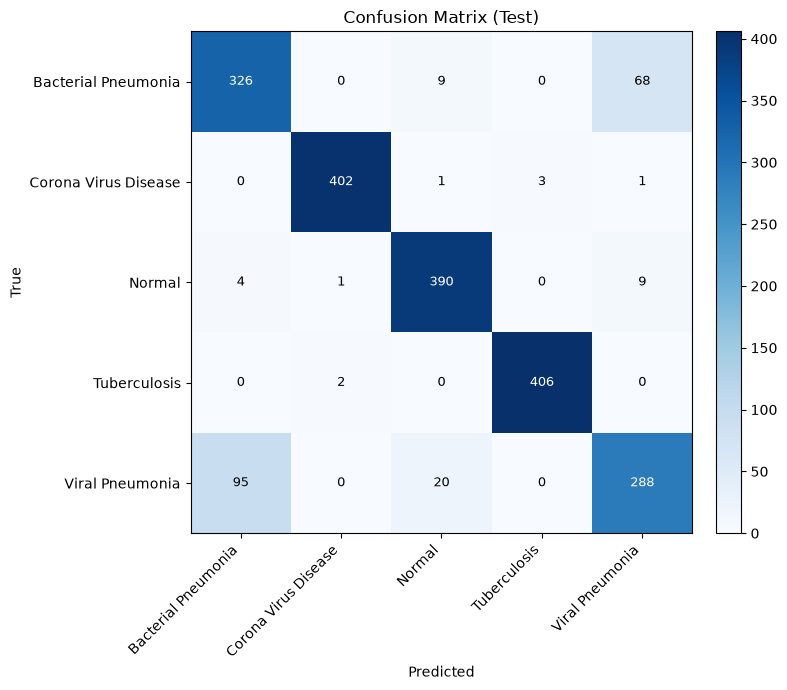

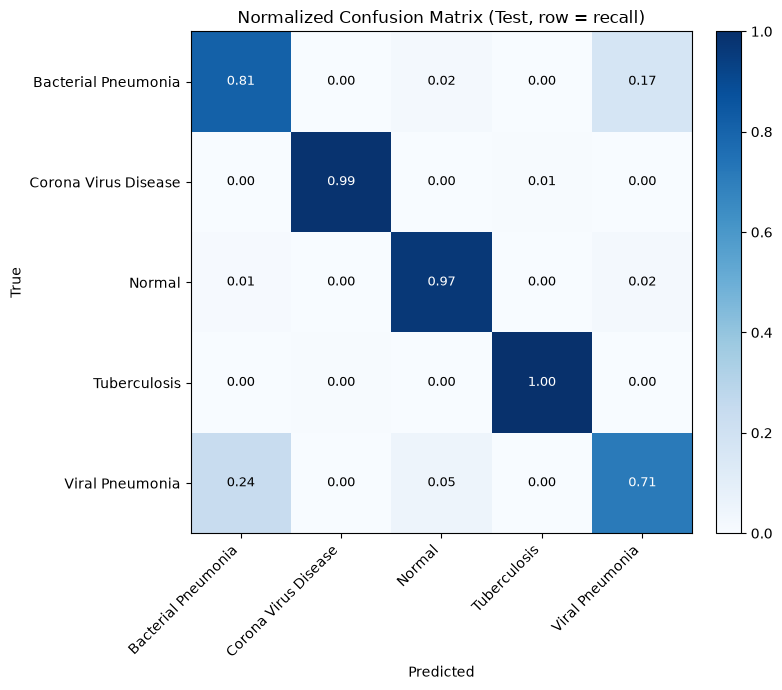

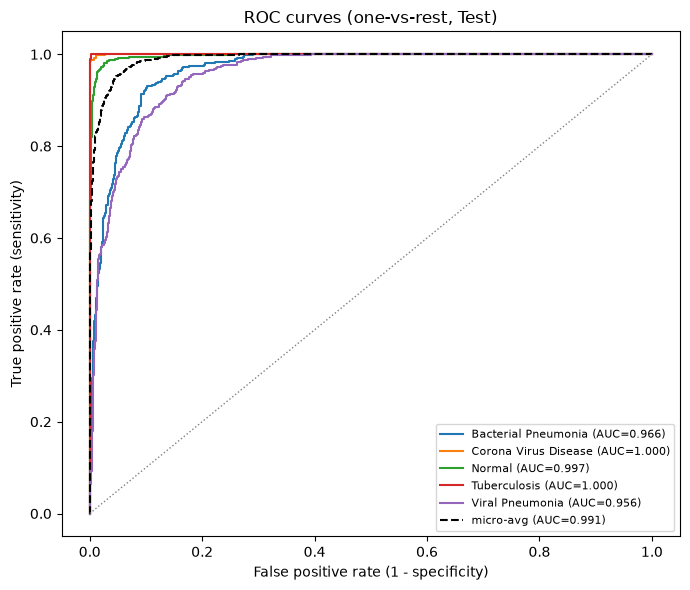

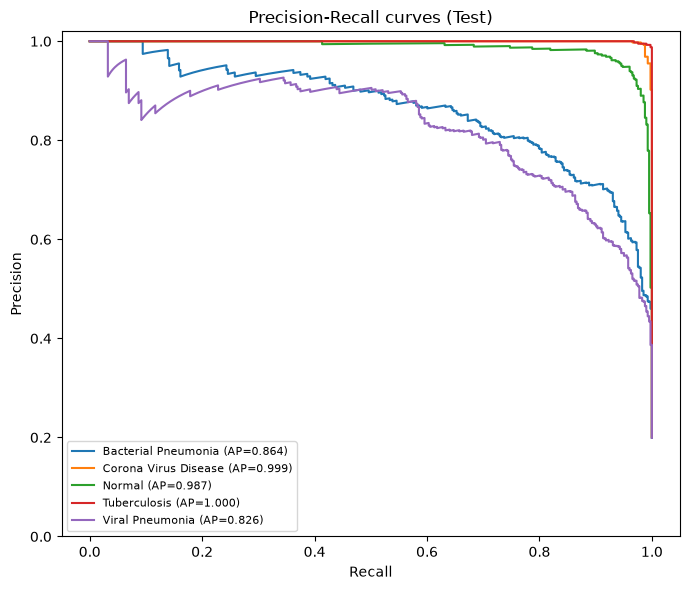

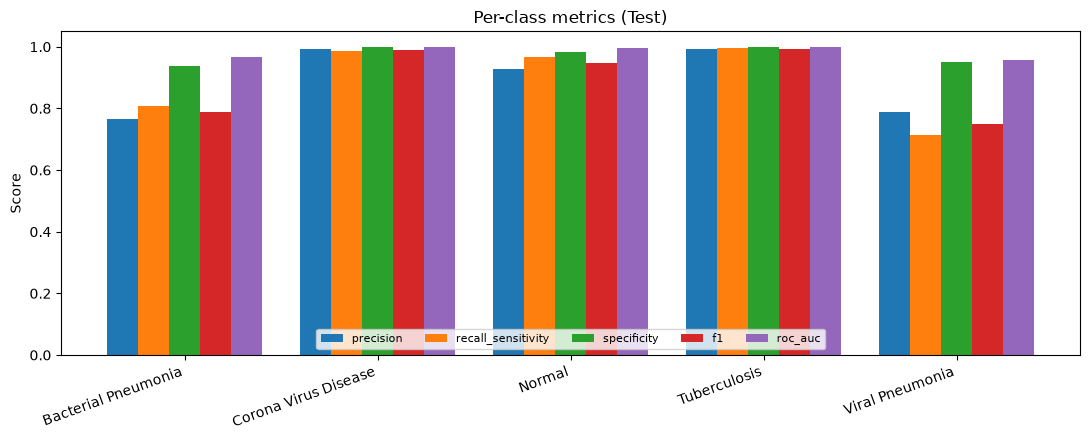

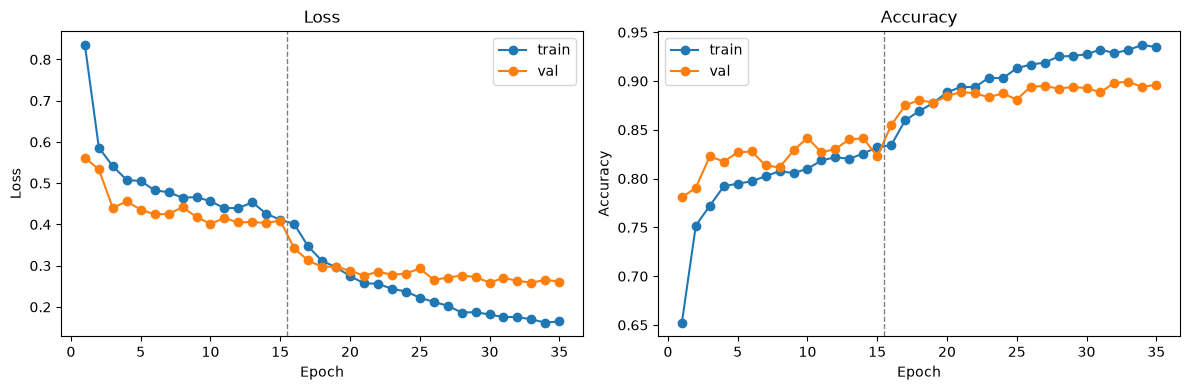

In [13]:
# ============================ TEST SET EVALUATION METRICS ============================
print("=== Final evaluation on TEST set ===")
te_loss, te_acc, preds, labels, probs = evaluate(model, test_loader, criterion)
print(f"Test loss={te_loss:.4f}  Test accuracy={te_acc:.4f}\n")

metrics = compute_metrics(labels, preds, probs, classes)
metrics["overall"]["loss"] = float(te_loss)
report = classification_report(labels, preds, target_names=classes, digits=4, zero_division=0)
print(report)
print_metrics(metrics)
print("\nConfusion matrix:\n", metrics["confusion_matrix"])

os.makedirs(OUT_ROOT, exist_ok=True)
save_metrics(metrics, report, OUT_ROOT, prefix="test")

figures = {
    "confusion_matrix.png": plot_confusion(metrics["confusion_matrix"], classes),
    "confusion_matrix_normalized.png": plot_confusion(metrics["confusion_matrix"], classes, normalize=True),
    "roc_curves.png": plot_roc_curves(labels, probs, classes),
    "pr_curves.png": plot_pr_curves(labels, probs, classes),
    "per_class_metrics.png": plot_per_class_metrics(metrics),
}
if history:
    figures["history.png"] = plot_history(history)
else:
    print("\n(No training history available.)")
for name, fig in figures.items():
    fig.savefig(os.path.join(OUT_ROOT, name), dpi=150, bbox_inches="tight")
print("Figures saved:", ", ".join(figures))
plt.show()

## Grad-CAM++ explanations

Heatmaps are computed on the **CBAM output** (attention-refined VGG16 features that feed both the CNN-pool
and the ViT branch), so they reflect the full hybrid model. Always selects the **5th test image** from each class.

Grad-CAM++ figure saved to E:\Lung_Disease_Dataset\dataset\output\gradcam_pp.png


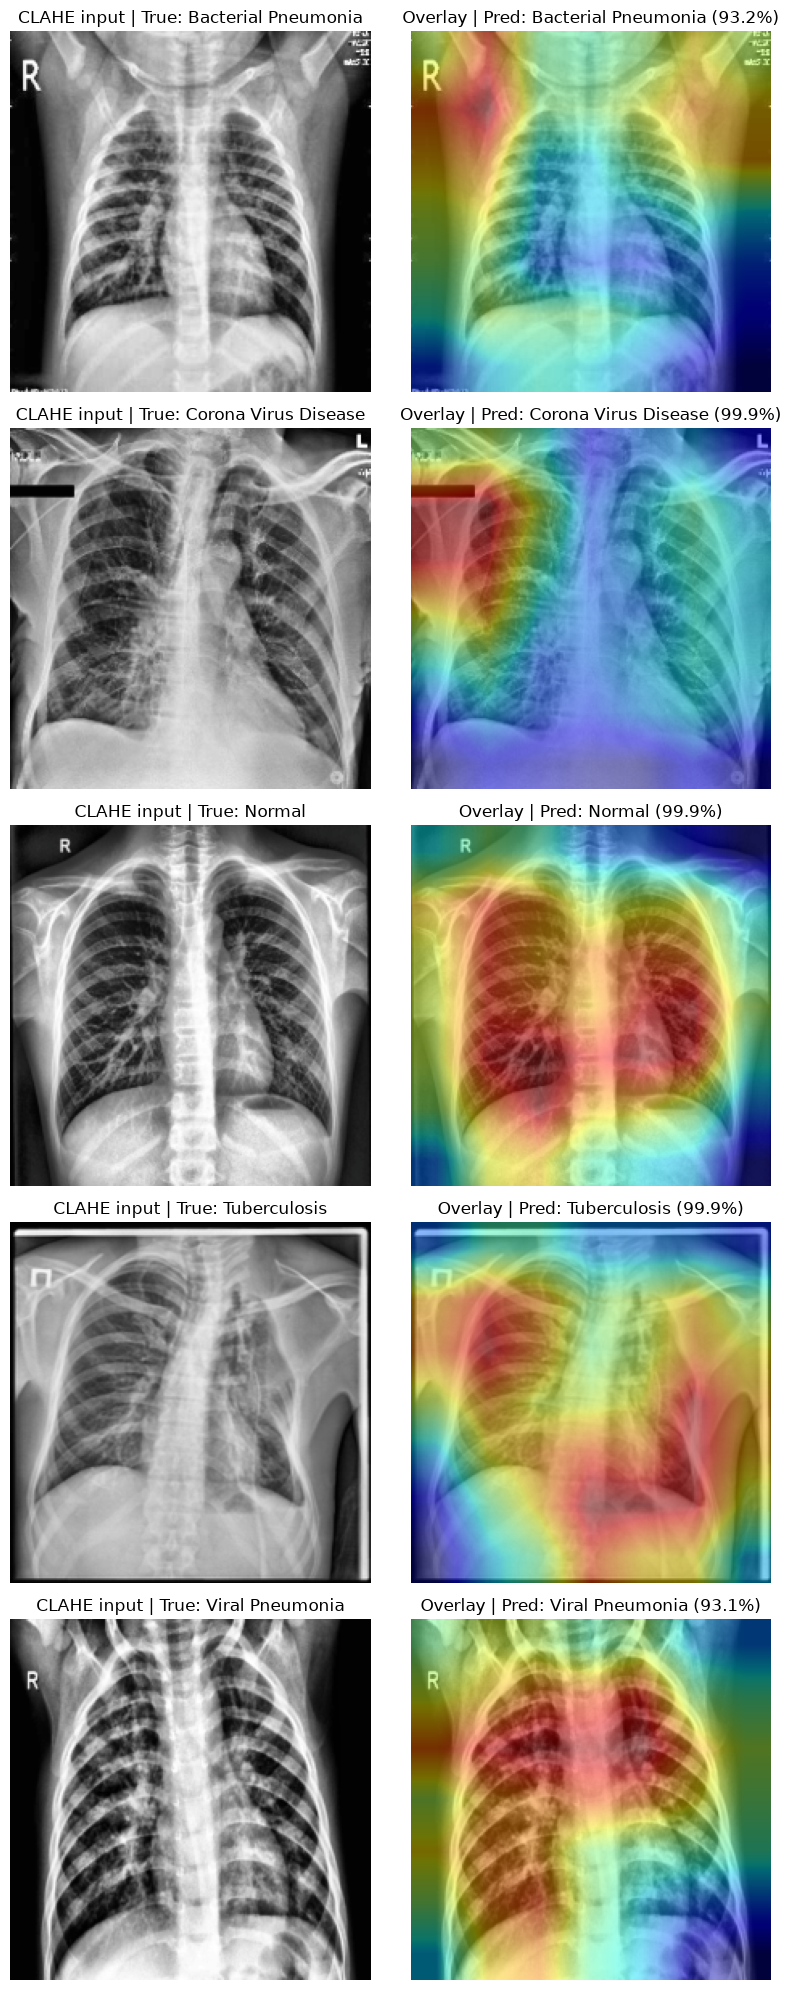

In [14]:
# ============================ GRAD-CAM++ VISUALIZATION ============================
cam_indices = select_gradcam_indices(test_loader.dataset, nth=GRADCAM_NTH_PER_CLASS, max_images=GRADCAM_IMAGES)
visualize_gradcam(model, test_loader.dataset, classes, cam_indices,
                  save_path=os.path.join(OUT_ROOT, "gradcam_pp.png"))

## Grad-CAM++ evaluation metrics (faithfulness)

| Metric | Meaning | Better |
|---|---|---|
| **Average Drop %** | confidence drop when the model sees only the CAM-highlighted region (image x CAM) | lower |
| **Increase in Confidence %** | % of images whose confidence *rises* on the highlighted region | higher |
| **Deletion AUC** | class probability while removing the most-salient pixels first | lower |
| **Insertion AUC** | class probability while revealing the most-salient pixels on a blurred image | higher |

A random-saliency baseline is reported alongside Deletion / Insertion for reference. Increase
`CAM_EVAL_SAMPLES` (or set it to `None`) for the full test set — slow on CPU.

  Grad-CAM++ eval: 50/50 images (24s)
=== Grad-CAM++ faithfulness metrics (50 test images) ===
  Average Drop (%)            : 17.59   (lower is better)
  Increase in Confidence (%)  : 24.00   (higher is better)
  Deletion AUC                : 0.4113   (lower is better; random = 0.4636)
  Insertion AUC               : 0.6179   (higher is better; random = 0.5153)


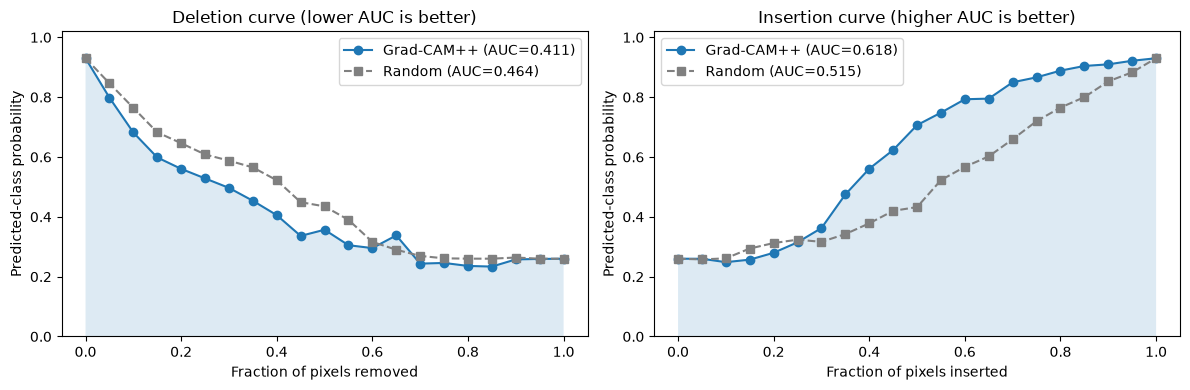

Saved gradcam_pp_metrics.json and gradcam_pp_deletion_insertion.png to E:\Lung_Disease_Dataset\dataset\output


In [15]:
# ============================ GRAD-CAM++ EVALUATION ============================
cam_results, cam_fracs, cam_curves = evaluate_gradcam(model, test_loader.dataset)
print_gradcam_metrics(cam_results)

with open(os.path.join(OUT_ROOT, "gradcam_pp_metrics.json"), "w") as f:
    json.dump(cam_results, f, indent=2)
fig = plot_deletion_insertion(cam_fracs, cam_curves, cam_results)
fig.savefig(os.path.join(OUT_ROOT, "gradcam_pp_deletion_insertion.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved gradcam_pp_metrics.json and gradcam_pp_deletion_insertion.png to {OUT_ROOT}")

In [16]:
# ============================ PREDICT YOUR OWN X-RAY (+ Grad-CAM++) ============================
MY_IMAGE = None  # e.g. r"E:\Lung_Disease_Dataset\dataset\test\Normal\some.png"
if MY_IMAGE:
    label, conf, all_probs = predict_image(model, MY_IMAGE, classes)
    top3 = sorted(all_probs.items(), key=lambda kv: -kv[1])[:3]
    print(f"Predicted: {label} (conf={conf:.3f})")
    print("top-3: " + ", ".join(f"{k}={v:.3f}" for k, v in top3))
else:
    print("Set MY_IMAGE to a file path and re-run this cell.")

Set MY_IMAGE to a file path and re-run this cell.


In [17]:
import torch
print(torch.xpu.is_available())
for i in range(torch.xpu.device_count()):
    print(i, torch.xpu.get_device_name(i))

True
0 Intel(R) Arc(TM) A750 Graphics
